EEG Condition Classification Using Machine Learning

This notebook extends the previous EEG analysis by treating the two subject conditions (eyes-open and eyes-closed)  as a binary classification problem. This experiment is exploratory and intended as a self-introduction to ML in an EEG context.


The first notebook investigated the Berger effect using spectral analysis, successfully finding it to be present in the subject's dataset. This second experiment builds on that work by exploring whether machine learning can recognise the differences between eyes-open and eyes-closed EEG recordings.


Furthermore, I will train two baseline models (Logistic regression, CSP + LDA) that will first be tested, and later on I will train and trial a CNN from EEGNet. This will allow for comparison of neural network models and to explore the interpretability of the EEG signals for determining eyes-opened vs eyes-closed conditions. Additionally, I would like to see if the more complicated CNN will make a tangible difference to accuracy as opposed to the baselines for this classification.



I expect that the logistic regression model utilsiing alpha-band features will perform well, due to the substantial increase in power (Berger effect) which was found in the first section of this experiment. I believe that the CNN will therefore have a modest increase in accuracy only.

1. Subject-wise evaluation split

12 participants - training

4 participants - validation

4 participants - testing

GroupKFold will ensure that epochs from each partipant are kept within one of these splits entirely, to prevent appearing in both training and testing. This will prevent prerformance inflation.

Furthermore, we will use 5-fold cross-validation, so there will be 5 training-evaluation rounds. Outer five-fold split selects test participants, and within this the inner splits devides the remaining devlopment particpants into either training or validation.

All 3 models will use the same held-out participants to evaluate accuracy after training. The dataset I am using has a limited number of participants.

1. Epoch Metadata table creation

Firstly, I put together an EEG pipeline which can be used to train the ML model. This is found in eeg_pipeline.py.

In [2]:
from pathlib import Path
import sys
%load_ext autoreload
%autoreload 2

print("Current working directory:", Path.cwd())
print("sys.path:")
for p in sys.path:
    print(" ", p)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Current working directory: c:\Users\aryan\OneDrive\Documents\EEG visualisation project\EEG analysis pipeline
sys.path:
  C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\python313.zip
  C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\DLLs
  C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib
  C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0
  
  C:\Users\aryan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages
  C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\site-packages


In [3]:
from eeg_ml import build_epoch_metadata

metadata = build_epoch_metadata(epochs_by_subject)

display(metadata.head(12))

display(
    metadata.groupby(["subject_id", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "eyes_open", 1: "eyes_closed"})
)

NameError: name 'epochs_by_subject' is not defined

Each row represents one retained EEG epoch. Participant IDs are used to keep subjects separated during evaluation; labels encode eyes open as 0 and eyes closed as 1.

In [18]:
print("Posterior alpha power")
print(f"Eyes closed: {alpha_power_posterior['eyes_closed']:.3e}")
print(f"Eyes open:   {alpha_power_posterior['eyes_open']:.3e}")

print("\nAll-channel alpha power")
print(f"Eyes closed: {alpha_power_all['eyes_closed']:.3e}")
print(f"Eyes open:   {alpha_power_all['eyes_open']:.3e}")

Posterior alpha power
Eyes closed: 1.342e+01
Eyes open:   7.118e+00

All-channel alpha power
Eyes closed: 8.184e+00
Eyes open:   4.876e+00


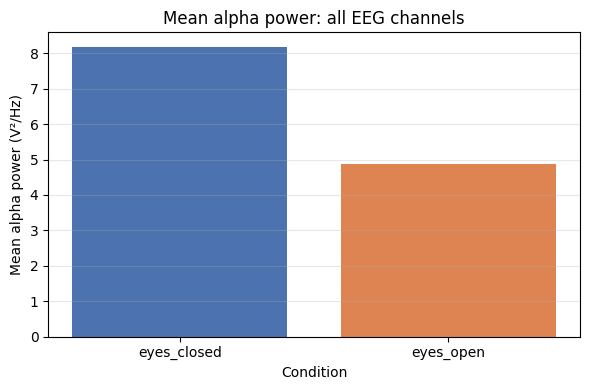

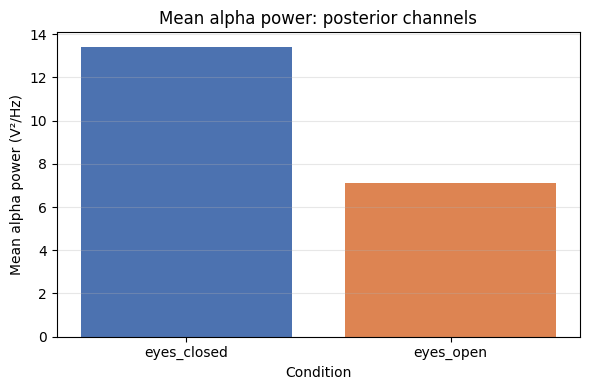

In [19]:
from eeg_pipeline import plot_alpha_power_comparison

fig_all = plot_alpha_power_comparison(
    alpha_power_all,
    title="Mean alpha power: all EEG channels",
)

fig_posterior = plot_alpha_power_comparison(
    alpha_power_posterior,
    title="Mean alpha power: posterior channels",
)

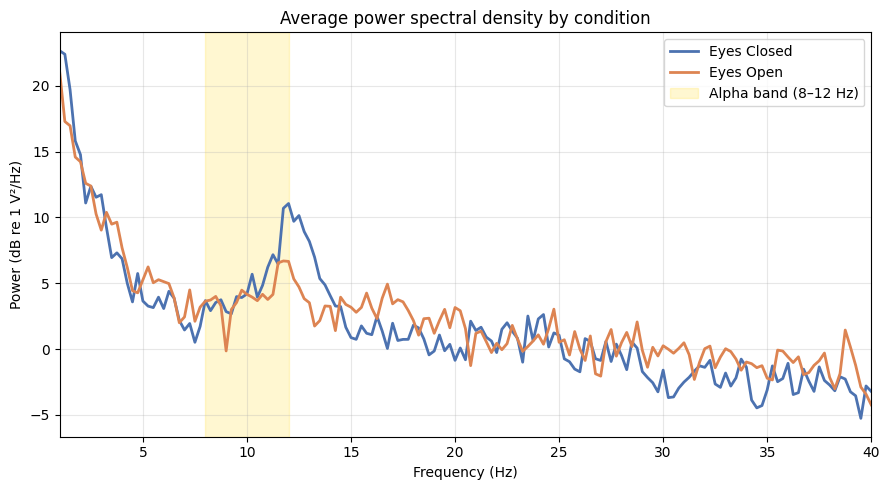

In [20]:
# posterior channels PSD comparison
from eeg_pipeline import plot_condition_psds

psd_figures = plot_condition_psds(
    epochs,
    picks=["O1", "OZ", "O2"],
    fmin=1.0,
    fmax=40.0,
)

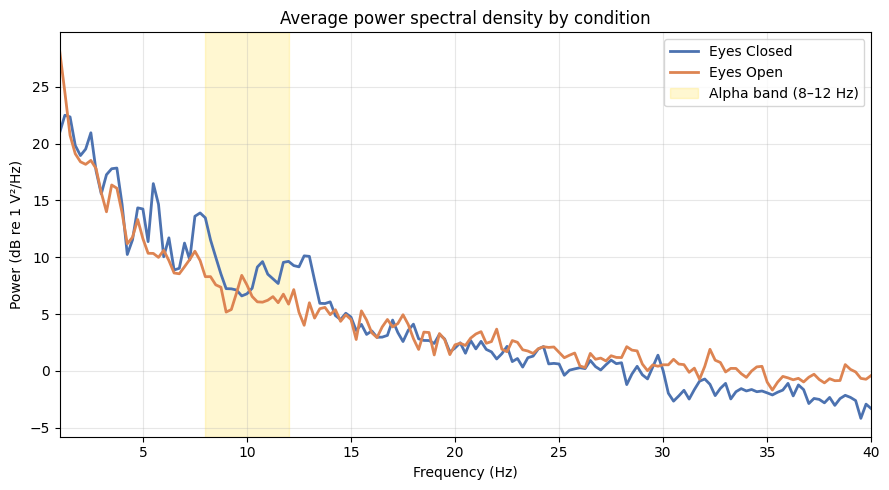

In [21]:
# all channel PSD comparison
from eeg_pipeline import plot_condition_psds

psd_figures = plot_condition_psds(
    epochs,
    fmin=1.0,
    fmax=40.0,
)

In [22]:
import importlib
import eeg_pipeline

importlib.reload(eeg_pipeline)

from eeg_pipeline import run_full_pipeline

In [25]:
results = run_full_pipeline(
    "subject_01",
    inspect_channels=False,
)

print(results["epochs"])
print("Bad channels:", results["raw_checked"].info["bads"])
print("Posterior channels used:", results["posterior_channels"])
print("All-channel alpha power:", results["alpha_power_all"])
print("Posterior alpha power:", results["alpha_power_posterior"])

Creating RawArray with float64 data, n_channels=16, n_times=119808
    Range : 0 ... 119807 =      0.000 ...   233.998 secs
Ready.
Bad channels: []
<Epochs | 10 events (all good), 0 – 10 s (baseline off), ~6.3 MiB, data loaded,
 'eyes_closed': 5
 'eyes_open': 5>
Bad channels: []
Posterior channels used: ['P7', 'P3', 'PZ', 'P4', 'P8', 'O1', 'OZ', 'O2']
All-channel alpha power: {'eyes_closed': 8.184139126724855, 'eyes_open': 4.875976724821354}
Posterior alpha power: {'eyes_closed': 13.41819717104067, 'eyes_open': 7.1178821797970295}


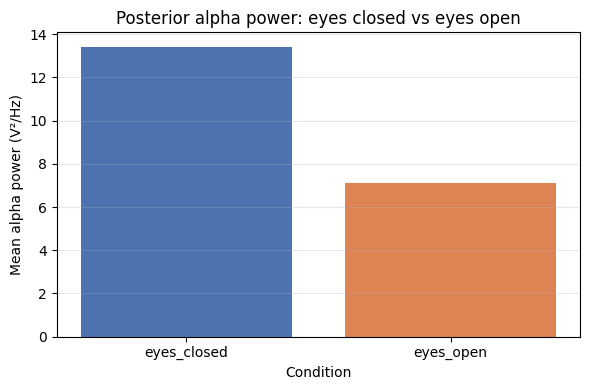

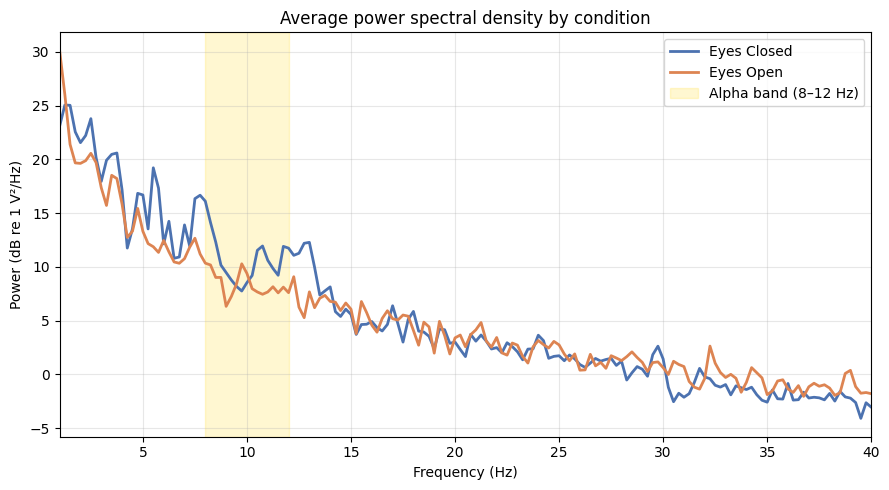

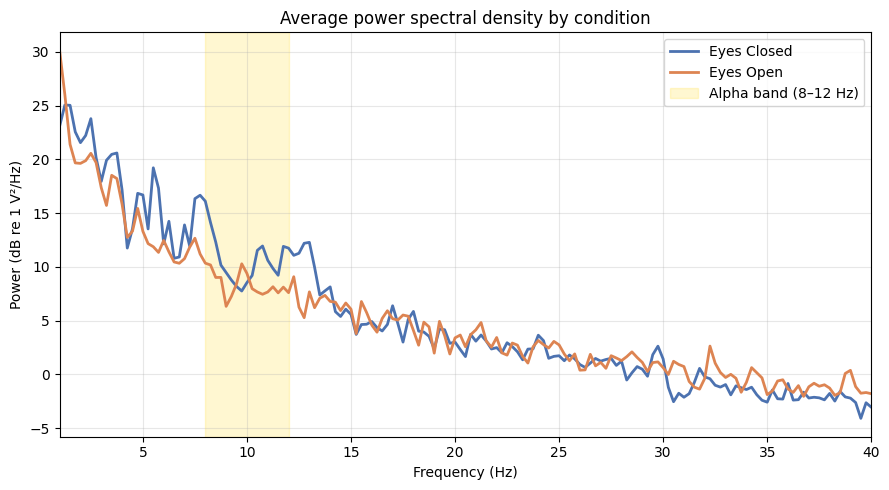

In [26]:
from eeg_pipeline import (
    plot_alpha_power_comparison,
    plot_condition_psds,
)

plot_alpha_power_comparison(
    results["alpha_power_posterior"],
    title="Posterior alpha power: eyes closed vs eyes open",
)

plot_condition_psds(
    results["epochs"],
    picks=results["posterior_channels"],
    fmin=1.0,
    fmax=40.0,
)

1d CNN - should be on pytorch

Kaggle learn website
